# Does the answer to "broader or narrower?" depend on how genre is defined? (RQ4, robustness of the main finding)

## Background and question
This project studies the Yambda dataset (Yandex Music listening logs) and asks: **for the same users, is what the recommender plays broader or narrower than what they choose themselves?**
Every listen is flagged *organic* (the user chose it) or *recommended*. Yambda is anonymous: tracks have no titles and **no genre labels**, so "broader" has to be defined through something we can measure.
The project uses *pseudo-genres*: clusters of the 128-dimensional audio embeddings found by spherical k-means. A user's listening is then "broader" if it spans more pseudo-genres.

That makes the main conclusion depend on a choice: the number of pseudo-genres, the clustering method, and the very idea of defining genre from sound. This notebook tests whether the conclusion survives when "genre" is defined in **many different ways**:

| Definition of genre / diversity | What it is | Why it is included |
|---|---|---|
| **Audio spread** | mean pairwise cosine distance between a user's tracks in audio space; no clusters | a measure of sound diversity that needs **no clustering at all** and no choice of k |
| **Artist IDs** | number of distinct artists | a **non-sound** definition that uses only the recorded metadata |
| **Sound pseudo-genres, hard** | k-means on audio, k = 8, 16, 32, 64, three random starts each | the project's definition, with the number of clusters varied |
| **Sound pseudo-genres, soft** | each track belongs *partly* to every pseudo-genre (softmax of the cosine to the centroids) | tests whether hard cluster borders matter |
| **Listening spread and listening pseudo-genres** | the same constructions on a *listening* embedding (item2vec: tracks played together get similar vectors) | defines diversity from **behaviour** instead of sound |

If the direction of the difference between the streams is the same under all of them, the conclusion does not depend on how genre was defined. If it flips, it does, and the report should say so.

## Fairness rules (the same for every definition)
- **Real listens only** (at least 50% of the track played), so skipped tracks do not count.
- **Distinct tracks**, not raw plays: organic listening is mostly replays of favourites, and counting plays would make it look narrower for a trivial reason.
- **The same users in both streams** (users with enough distinct tracks in both), and **equal-sized samples**: the first 40 distinct tracks of each user in each stream (30 and 100 are tested in section 5).
- Everything is an **association** in Yambda-50M; it says nothing about why the streams differ.

## Plan: what each step is for
| # | Step | What we want to learn |
|---|---|---|
| 1 | Data and user samples | who is compared, and with which tracks |
| 2 | Genre definitions | build every definition from the same tracks |
| 3 | Comparison of the streams | for each definition, is recommended listening broader or narrower, and how sure are we? |
| 4 | Sensitivity | does the answer change with the track universe and when the most popular tracks are removed? |
| 5 | Sample size | does the answer depend on how many tracks per stream we require (N = 30, 40, 100)? |
| 6 | Early versus late | does the variety of recommended listening fade as listening goes on, compared with organic listening? |
| 7 | Summary | does the conclusion depend on the definition? |

*Prerequisites:* the processed embeddings `data/processed/emb50m_*.npy` (created by `scripts/extract_embeddings_50m.py`), the raw Yambda-50M events and the artist mapping in `data/raw/yambda/`.
Run time: roughly 10 minutes. Memory: below 3 GB.

## 0. Setup and parameters

In [1]:
from pathlib import Path
import time
import zlib
import logging
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
from scipy import stats
from scipy.sparse import csr_matrix
from gensim.models import Word2Vec

# ---------------- parameters (change here, then Run All) ----------------
REAL_PCT = 50            # a real listen = at least this % of the track played
N_TRACKS = 40            # distinct tracks per user and stream in the samples (main setting)
N_SENS = [30, 40, 100]   # sample sizes compared in the sensitivity section
WIN = 10                 # window length (tracks) of the position analysis
SESSION_GAP_S = 30 * 60  # a gap longer than this between two listens starts a new session (item2vec)
SESSION_CAP = 50
TOKEN_BUDGET = 12_000_000    # training tokens of the listening embedding
VEC, WINDOW, NEG, EPOCHS, MIN_COUNT = 64, 5, 10, 5, 20
W2V_WORKERS = 8
K_GRID = [8, 16, 32, 64]
K_SOFT = 32
N_FIT = 150_000
N_SEEDS = 3
TRIM_Q = 0.80            # popularity-trimmed sample: drop tracks above this quantile of "users per track"
N_BOOT = 1000
SEED = 42

rng = np.random.default_rng(SEED)
logging.getLogger("gensim").setLevel(logging.ERROR)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
REAL, NULL, ACC = "#264653", "#9aa0a6", "#e76f51"

ROOT = Path.cwd()
while not (ROOT / "data" / "raw" / "yambda").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Could not find data/raw/yambda above " + str(Path.cwd()))
    ROOT = ROOT.parent
DATA, PROC = ROOT / "data" / "raw" / "yambda", ROOT / "data" / "processed"
print("project root:", ROOT)

project root: C:\MSc DTU\Semester 3\01. CTDS\Music


## 1. Data and user samples

### 1.1 The events
We read all real listens of Yambda-50M (both streams) with the columns we need, and sort them by user and time. Memory is kept low by storing compact integer types.

In [2]:
t0 = time.time()
tbl = pq.read_table(DATA / "flat/50m/multi_event.parquet", columns=["uid", "item_id", "timestamp", "is_organic"],
                    filters=[("event_type", "=", "listen"), ("played_ratio_pct", ">=", REAL_PCT)])
uid = tbl["uid"].to_numpy().astype(np.int64); item = tbl["item_id"].to_numpy().astype(np.int64)
ts = tbl["timestamp"].to_numpy().astype(np.int64); org = tbl["is_organic"].to_numpy().astype(np.int8); del tbl
order = np.lexsort((ts, uid)); uid, item, ts, org = uid[order], item[order], ts[order], org[order]; del order
uid_idx = np.unique(uid, return_inverse=True)[1].astype(np.int32); n_users = int(uid_idx.max()) + 1
uid, item, ts = uid.astype(np.int32), item.astype(np.int32), ts.astype(np.int32)
print(f"{len(item):,} real listens of {n_users:,} users; {org.mean():.1%} organic ({time.time() - t0:.0f} s)")

emb_ids = np.load(PROC / "emb50m_item_ids.npy")
EN = np.load(PROC / "emb50m_norm.npy")                                 # (848k, 128), unit length
L = int(max(item.max(), emb_ids.max())) + 1
item_row = np.full(L, -1, dtype=np.int64); item_row[emb_ids] = np.arange(len(emb_ids))
users_per_item = np.bincount(np.unique(uid_idx.astype(np.int64) * (1 << 32) + item)[:, None].ravel() & 0xFFFFFFFF, minlength=L)
def first_map(path, col):
    mp = pd.read_parquet(path).drop_duplicates("item_id"); arr = np.full(L, -1, dtype=np.int64)
    ids = mp["item_id"].to_numpy(); ok = ids < L; arr[ids[ok]] = mp[col].to_numpy()[ok]; return arr
art_of_item = first_map(DATA / "artist_item_mapping.parquet", "artist_id")
art_of_item = np.where(art_of_item >= 0, art_of_item, -1 - np.arange(L))    # tracks without artist information count as their own artist

29,439,278 real listens of 9,209 users; 48.0% organic (10 s)


### 1.2 A listening embedding for "genre from behaviour"
**What it is.** *item2vec*: sessions (runs of listens without a pause of more than 30 minutes) are treated as sentences and tracks as words, and a skip-gram model learns a vector per track so that tracks played in the same sessions get similar vectors. It uses listening behaviour only and no audio.

**Why trained on both streams together.** If we trained it on the organic stream only, organic listening could look more coherent in its own embedding, and the reverse for the recommended stream. Pooling the real listens of both streams (all sessions of a user as they happened) keeps the definition of "listening genre" neutral between the streams.
We use a random 12 million tokens of the pooled sessions to bound the training time. Only tracks with at least 20 plays get a vector, so listening-based definitions describe well-known tracks.

**Is the leading direction popularity?** Embeddings of this kind sometimes have a direction that reflects how often a track occurs. We measure it; if it is strongly related to popularity we would remove it, otherwise we keep all directions.

In [3]:
def rank_in_sorted_groups(g):
    start = np.r_[0, np.flatnonzero(g[1:] != g[:-1]) + 1]
    return np.arange(len(g)) - np.repeat(start, np.diff(np.r_[start, len(g)]))

t0 = time.time()
new_sess = np.r_[True, uid[1:] != uid[:-1]] | np.r_[True, (ts[1:].astype(np.int64) - ts[:-1]) > SESSION_GAP_S]
sid = np.cumsum(new_sess).astype(np.int64) - 1
_, first = np.unique(sid * (int(item.max()) + 1) + item, return_index=True); first.sort()          # each track once per session, in order of play
s_, it_ = sid[first], item[first].astype(np.int64)
keep = rank_in_sorted_groups(s_) < SESSION_CAP; s_, it_ = s_[keep], it_[keep]
_, inv, cnt = np.unique(s_, return_inverse=True, return_counts=True)
ok = (cnt >= 2)[inv]; tok, sess = it_[ok], np.unique(inv[ok], return_inverse=True)[1]
n_s = sess.max() + 1; lens = np.bincount(sess, minlength=n_s); shuf = rng.permutation(n_s)
chosen = np.sort(shuf[np.cumsum(lens[shuf]) <= TOKEN_BUDGET]); msk = np.isin(sess, chosen)
tok, sess = tok[msk], np.unique(sess[msk], return_inverse=True)[1]; starts = np.r_[0, np.flatnonzero(sess[1:] != sess[:-1]) + 1, len(tok)]
print(f"pooled sessions: {len(starts) - 1:,} sessions, {len(tok):,} tokens ({time.time() - t0:.0f} s)")

class Corpus:
    def __iter__(self):
        for a, b in zip(starts[:-1], starts[1:]): yield [str(x) for x in tok[a:b]]
def det_hash(s): return zlib.crc32(s.encode())
w2v = Word2Vec(Corpus(), vector_size=VEC, window=WINDOW, sg=1, negative=NEG, min_count=MIN_COUNT, sample=1e-4, epochs=EPOCHS, workers=W2V_WORKERS, seed=SEED, hashfxn=det_hash)
keys = w2v.wv.index_to_key; v_ids = np.array([int(k) for k in keys]); V = np.asarray(w2v.wv.vectors, dtype=np.float64); v_cnt = np.array([w2v.wv.get_vecattr(k, "count") for k in keys])
okv = item_row[v_ids] >= 0; v_ids, V, v_cnt = v_ids[okv], V[okv], v_cnt[okv]
cidx = np.full(L, -1, dtype=np.int64); cidx[v_ids] = np.arange(len(v_ids))                    # item -> row of the listening embedding
Vc = V - V.mean(0); _, S_, Vt_ = np.linalg.svd(Vc, full_matrices=False)
print(f"listening embedding: {len(v_ids):,} tracks with an audio embedding and at least {MIN_COUNT} plays ({time.time() - t0:.0f} s)")
print(f"leading direction: {S_[0] ** 2 / (S_ ** 2).sum():.1%} of the variance, correlation with log plays {np.corrcoef(Vc @ Vt_[0], np.log1p(v_cnt))[0, 1]:+.2f}")
LV = (Vc / np.linalg.norm(Vc, axis=1, keepdims=True)).astype(np.float32)                      # listening vectors, centred, unit length

pooled sessions: 972,314 sessions, 11,999,999 tokens (6 s)


listening embedding: 75,262 tracks with an audio embedding and at least 20 plays (123 s)
leading direction: 13.9% of the variance, correlation with log plays -0.14


### 1.3 Reading the listening embedding

The listening embedding covers **75,262 tracks** (those with an audio embedding and at least 20 plays in the 12.0 million training tokens of pooled sessions). Its leading direction carries 13.9% of the variance and correlates only +0.14 with log plays, so it does not mostly encode popularity and we keep all directions.
The listening-based definitions describe these well-known tracks only; the sound-based ones are also computed for all embedded tracks (section 4).

### 1.4 The user samples
**What we do.** For each user and stream we take the **first 40 distinct tracks** in time order, and keep users who have at least 40 in both streams. (An earlier version required 100, which left out 44% of all users; 40 distinct tracks is a normal listening stretch, and section 5 shows the results for 30 and 100.) We build three samples:
1. **All embedded tracks:** every track that has an audio embedding (the universe of the sound-based definitions).
2. **Tracks with audio and listening vectors:** the universe in which *all* definitions can be computed, so they can be compared on identical users and tracks. This is the **main sample**.
3. **Popularity-trimmed:** the main sample without the 20% most popular tracks (by number of users), which tests whether the result is only about hits.

**What we want to learn.** How many users and which tracks each comparison rests on.

In [4]:
def rank_in_group(g):
    order = np.argsort(g, kind="stable"); gs = g[order]
    start = np.r_[0, np.flatnonzero(gs[1:] != gs[:-1]) + 1]
    rank = np.empty(len(g), dtype=np.int64); rank[order] = np.arange(len(gs)) - np.repeat(start, np.diff(np.r_[start, len(gs)])); return rank

def build_sample(in_universe, n_tracks=N_TRACKS):
    # returns users and items of shape (U, 2, n); axis 1: 0 = recommended, 1 = organic. First n distinct tracks per user and stream.
    m = in_universe[item]
    ui, it, og = uid_idx[m].astype(np.int64), item[m].astype(np.int64), org[m].astype(np.int64)
    _, fi = np.unique((ui << 33) | (it << 1) | og, return_index=True); fi.sort()
    ui, it, og = ui[fi], it[fi], og[fi]
    g = ui * 2 + og; rk = rank_in_group(g)
    cnt = np.bincount(g, minlength=2 * n_users).reshape(n_users, 2); elig = (cnt >= n_tracks).all(axis=1)
    sel = (rk < n_tracks) & elig[ui]; gs, its = g[sel], it[sel]
    o = np.argsort(gs, kind="stable"); gs, its = gs[o], its[o]
    return gs[::n_tracks][::2] // 2, its.reshape(-1, 2, n_tracks)

in_all = item_row >= 0
in_common = cidx >= 0
thr = np.quantile(users_per_item[in_common], TRIM_Q)
in_trim = in_common & (users_per_item < thr)
samples = {}
for name, mask in [("all embedded tracks", in_all), ("tracks with audio and listening vectors (main)", in_common), ("main sample without the 20% most popular tracks", in_trim)]:
    u_, it_ = build_sample(mask); samples[name] = it_
    print(f"{name}: {len(u_):,} users with at least {N_TRACKS} distinct tracks in both streams; {len(np.unique(it_)):,} distinct tracks used")

all embedded tracks: 6,618 users with at least 40 distinct tracks in both streams; 108,098 distinct tracks used


tracks with audio and listening vectors (main): 6,441 users with at least 40 distinct tracks in both streams; 59,258 distinct tracks used


main sample without the 20% most popular tracks: 3,958 users with at least 40 distinct tracks in both streams; 52,870 distinct tracks used


### 1.5 Reading the samples

Yambda-50M has 29,439,278 real listens by 9,209 users (48% organic). Users with at least 40 distinct tracks in **both** streams:

| Sample | Users | Distinct tracks used |
|---|---|---|
| All embedded tracks | 6,618 | 108,098 |
| Main: tracks with audio and listening vectors | **6,441** | 59,258 |
| Main without the 20% most popular tracks | 3,958 | 52,870 |

The conclusions therefore concern users with at least a short listening history in both streams (70% of all users in the main sample, 43% in the popularity-trimmed one), and the first 40 distinct tracks of each stream. With the earlier requirement of 100 tracks the main sample had 5,171 users (56%).

## 2. Building every definition of genre

**Sound pseudo-genres (hard).** Spherical k-means on the audio embeddings (each scaled to unit length): a track goes to the centroid with the highest cosine similarity, each centroid is the re-normalised mean of its members, and k-means++ seeding spreads the initial centres.
Centroids are fitted on a random sample of 150,000 of the 848k embedded tracks and **every** track is assigned to the nearest centroid. We use k = 8, 16, 32, 64 and three random starts for each, because k-means depends on its start.

**Sound pseudo-genres (soft).** For k = 32, a track's membership in pseudo-genre $j$ is $\mathrm{softmax}_j(\cos(x,c_j)/\tau)$. The temperature $\tau$ decides how soft the memberships are: very small values reproduce the hard assignment, very large values give equal memberships.
We choose $\tau$ so that the **average largest membership is 0.5** (neither nearly hard nor nearly flat), and check half and double that value.

**Listening pseudo-genres (hard).** The same spherical k-means on the listening vectors of section 1.2 (k = 8, 16, 32, 64, three starts), so "genre" here means a group of tracks that are played together.

**The measures per user and stream** (for the 40 tracks of the sample):
- *Number of distinct pseudo-genres* and *entropy* of the distribution of the tracks over pseudo-genres (higher means broader);
- *novel-genre share*: the share of one stream's tracks that fall in pseudo-genres **absent from the user's other stream** (a measure of exploration; recommended-novel against organic-novel);
- for soft memberships: the **entropy of the user's average membership vector**;
- *spread*: $1-$ the mean pairwise cosine similarity of the user's tracks (audio or listening vectors); *distinct artists* for the artist definition.
In every case, a **higher value means broader listening**.

In [5]:
def spherical_kmeans(X, k, seed, n_iter=60):
    r_ = np.random.default_rng(seed); n_ = len(X)
    Cn = np.empty((k, X.shape[1]), dtype=np.float32); Cn[0] = X[r_.integers(n_)]
    dist = 1 - X @ Cn[0]
    for j in range(1, k):                                   # k-means++ seeding with cosine distance
        pr = np.maximum(dist, 0) ** 2; Cn[j] = X[r_.choice(n_, p=pr / pr.sum())]
        dist = np.minimum(dist, 1 - X @ Cn[j])
    labels = np.full(n_, -1)
    for _ in range(n_iter):
        new = np.argmax(X @ Cn.T, axis=1)
        if (new == labels).mean() > 0.9995:
            labels = new; break
        labels = new
        sums = csr_matrix((np.ones(n_, np.float32), (labels, np.arange(n_))), shape=(k, n_)) @ X
        nrm = np.linalg.norm(sums, axis=1, keepdims=True)
        empty = nrm[:, 0] == 0
        sums[empty] = X[r_.integers(n_, size=empty.sum())]; nrm[empty] = 1
        Cn = (sums / np.maximum(nrm, 1e-9)).astype(np.float32)
    return Cn

t0 = time.time()
fit_idx = rng.choice(len(EN), N_FIT, replace=False)
cent = {(k, s): spherical_kmeans(EN[fit_idx], k, SEED + 100 * s) for k in K_GRID for s in range(N_SEEDS)}
def assign(Xm, Cn):
    out = np.empty(len(Xm), dtype=np.int8)
    for s0 in range(0, len(Xm), 200_000): out[s0:s0 + 200_000] = np.argmax(Xm[s0:s0 + 200_000] @ Cn.T, axis=1)
    return out
lab_sound = {}
for key, Cn in cent.items():
    a = np.full(L, -1, dtype=np.int8); a[emb_ids] = assign(EN, Cn); lab_sound[key] = a
LVc = LV.astype(np.float32)
lab_listen = {}
for k in K_GRID:
    for s in range(N_SEEDS):
        Cn = spherical_kmeans(LVc, k, SEED + 100 * s); a = np.full(L, -1, dtype=np.int8); a[v_ids] = assign(LVc, Cn); lab_listen[(k, s)] = a
print(f"sound and listening pseudo-genres built ({time.time() - t0:.0f} s)")

# soft memberships: choose the temperature so that the average largest membership is 0.5
Csoft = cent[(K_SOFT, 0)]; probe = EN[rng.choice(len(EN), 20_000, replace=False)] @ Csoft.T
def mean_max_membership(tau):
    z = probe / tau; z -= z.max(1, keepdims=True); p = np.exp(z); p /= p.sum(1, keepdims=True); return p.max(1).mean()
lo, hi = 1e-3, 1.0
for _ in range(40):
    mid = np.sqrt(lo * hi)
    if mean_max_membership(mid) > 0.5: lo = mid
    else: hi = mid
TAU = float(np.sqrt(lo * hi))
print(f"temperature tau = {TAU:.4f} (average largest membership {mean_max_membership(TAU):.2f}); half: {mean_max_membership(TAU / 2):.2f}, double: {mean_max_membership(TAU * 2):.2f}")
def soft_table(tau):
    out = np.empty((len(EN), K_SOFT), dtype=np.float32)
    for s0 in range(0, len(EN), 100_000):
        z = (EN[s0:s0 + 100_000] @ Csoft.T) / tau; z -= z.max(1, keepdims=True); p = np.exp(z); out[s0:s0 + 100_000] = p / p.sum(1, keepdims=True)
    return out

sound and listening pseudo-genres built (47 s)


temperature tau = 0.1272 (average largest membership 0.50); half: 0.80, double: 0.18


## 3. Comparing the streams under every definition

**What we do.** For each definition and each sample we compute the measure for every user in both streams and compare **within each user** (recommended minus organic). We report:
- the **median** value in each stream,
- **P(recommended > organic)**: the share of users whose recommended value is higher than their organic value (ties count half). It is 0.5 if the streams do not differ, above 0.5 if recommended listening is broader for most users, below 0.5 if it is narrower. It has the same scale for every definition, which makes the definitions comparable,
- a **95% bootstrap interval** of that share (resampling users 1000 times; for definitions with several random starts, the interval is for the average over starts),
- the share across the individual random starts (minimum and maximum).

**What we want to learn.** For each definition: is recommended listening broader (P above 0.5 with an interval that excludes 0.5), narrower (below), or not different? And do the definitions agree?

In [6]:
def entropy_bits(p): return -(np.where(p > 0, p * np.log2(np.where(p > 0, p, 1)), 0)).sum(-1)
def genre_counts(items, lab_item, K):
    U = items.shape[0]; G = lab_item[items].astype(np.int64)
    idx = (np.arange(U)[:, None, None] * 2 + np.arange(2)[None, :, None]) * K + G
    return np.bincount(idx.ravel(), minlength=U * 2 * K).reshape(U, 2, K)
def hard_measures(items, lab_item, K):
    cnt = genre_counts(items, lab_item, K); n = items.shape[2]; ent = entropy_bits(cnt / n); dist = (cnt > 0).sum(-1)
    return {"distinct genres": (dist[:, 1], dist[:, 0]), "genre entropy (bits)": (ent[:, 1], ent[:, 0]),
            "novel-genre share": ((cnt[:, 1] * (cnt[:, 0] == 0)).sum(-1) / n, (cnt[:, 0] * (cnt[:, 1] == 0)).sum(-1) / n)}
def spread_measure(items, table, rowmap):
    U, _, n = items.shape; rows = rowmap[items]; S = np.empty((U, 2, table.shape[1]), dtype=np.float32)
    for s0 in range(0, U, 400): S[s0:s0 + 400] = table[rows[s0:s0 + 400]].sum(axis=2)
    sp = 1 - ((S.astype(np.float64) ** 2).sum(-1) - n) / (n * (n - 1)); return sp[:, 1], sp[:, 0]
def artist_measure(items):
    A = np.sort(art_of_item[items], axis=2); d = 1 + (np.diff(A, axis=2) != 0).sum(axis=2); return d[:, 1], d[:, 0]
def soft_measure(items, Msoft):
    U = items.shape[0]; out = np.empty((U, 2))
    for s0 in range(0, U, 500): out[s0:s0 + 500] = entropy_bits(Msoft[item_row[items[s0:s0 + 500]]].mean(axis=2))
    return out[:, 1], out[:, 0]

def summarise(per_seed, sample, family, definition, measure):
    # per_seed: list of (organic, recommended) arrays over users
    z = np.mean([(r > o) + 0.5 * (r == o) for o, r in per_seed], axis=0)
    boot = z[rng.integers(0, len(z), (N_BOOT, len(z)))].mean(axis=1)
    ps = [((r > o) + 0.5 * (r == o)).mean() for o, r in per_seed]
    o0, r0 = per_seed[0]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        try: pw = stats.wilcoxon(r0 - o0).pvalue
        except ValueError: pw = np.nan
    return dict(sample=sample, family=family, definition=definition, measure=measure, users=len(z), organic_median=np.mean([np.median(o) for o, _ in per_seed]),
                recommended_median=np.mean([np.median(r) for _, r in per_seed]), P=z.mean(), lo=np.quantile(boot, 0.025), hi=np.quantile(boot, 0.975), P_min=min(ps), P_max=max(ps), p_wilcoxon_first_start=pw)

def evaluate_sample(name, items, with_listening):
    rows = []
    rows.append(summarise([spread_measure(items, EN, item_row)], name, "no clustering", "audio spread", "spread"))
    if with_listening: rows.append(summarise([spread_measure(items, LV, cidx)], name, "no clustering", "listening spread", "spread"))
    rows.append(summarise([artist_measure(items)], name, "artist IDs", "distinct artists", "distinct artists"))
    for k in K_GRID:
        res = [hard_measures(items, lab_sound[(k, s)], k) for s in range(N_SEEDS)]
        for meas in res[0]: rows.append(summarise([r_[meas] for r_ in res], name, "sound pseudo-genres (hard)", f"k = {k}", meas))
    for mult, lab in [(0.5, "tau / 2"), (1, "tau"), (2, "tau x 2")]:
        rows.append(summarise([soft_measure(items, soft_table(TAU * mult))], name, "sound pseudo-genres (soft)", f"k = {K_SOFT}, {lab}", "entropy of average membership (bits)"))
    if with_listening:
        for k in K_GRID:
            res = [hard_measures(items, lab_listen[(k, s)], k) for s in range(N_SEEDS)]
            for meas in res[0]: rows.append(summarise([r_[meas] for r_ in res], name, "listening pseudo-genres (hard)", f"k = {k}", meas))
    return rows

t0 = time.time(); all_rows = []
for name, items in samples.items():
    all_rows += evaluate_sample(name, items, with_listening=(name != "all embedded tracks")); print(f"{name}: done ({time.time() - t0:.0f} s)")
res = pd.DataFrame(all_rows)
MAIN = "tracks with audio and listening vectors (main)"
show = lambda d: d[["family", "definition", "measure", "organic_median", "recommended_median", "P", "lo", "hi", "P_min", "P_max"]].to_string(index=False, float_format=lambda x: f"{x:.3f}")
print(f"\nMAIN SAMPLE ({res[res['sample'] == MAIN].users.iloc[0]:,} users):"); print(show(res[res["sample"] == MAIN]))

all embedded tracks: done (3 s)


tracks with audio and listening vectors (main): done (7 s)


main sample without the 20% most popular tracks: done (10 s)

MAIN SAMPLE (6,441 users):
                        family       definition                              measure  organic_median  recommended_median     P    lo    hi  P_min  P_max
                 no clustering     audio spread                               spread           0.662               0.642 0.416 0.405 0.428  0.416  0.416
                 no clustering listening spread                               spread           0.699               0.660 0.363 0.350 0.374  0.363  0.363
                    artist IDs distinct artists                     distinct artists          30.000              35.000 0.784 0.774 0.793  0.784  0.784
    sound pseudo-genres (hard)            k = 8                      distinct genres           5.000               5.000 0.442 0.432 0.451  0.438  0.445
    sound pseudo-genres (hard)            k = 8                 genre entropy (bits)           1.778               1.679 0.427 0.416 0.438  0.424 

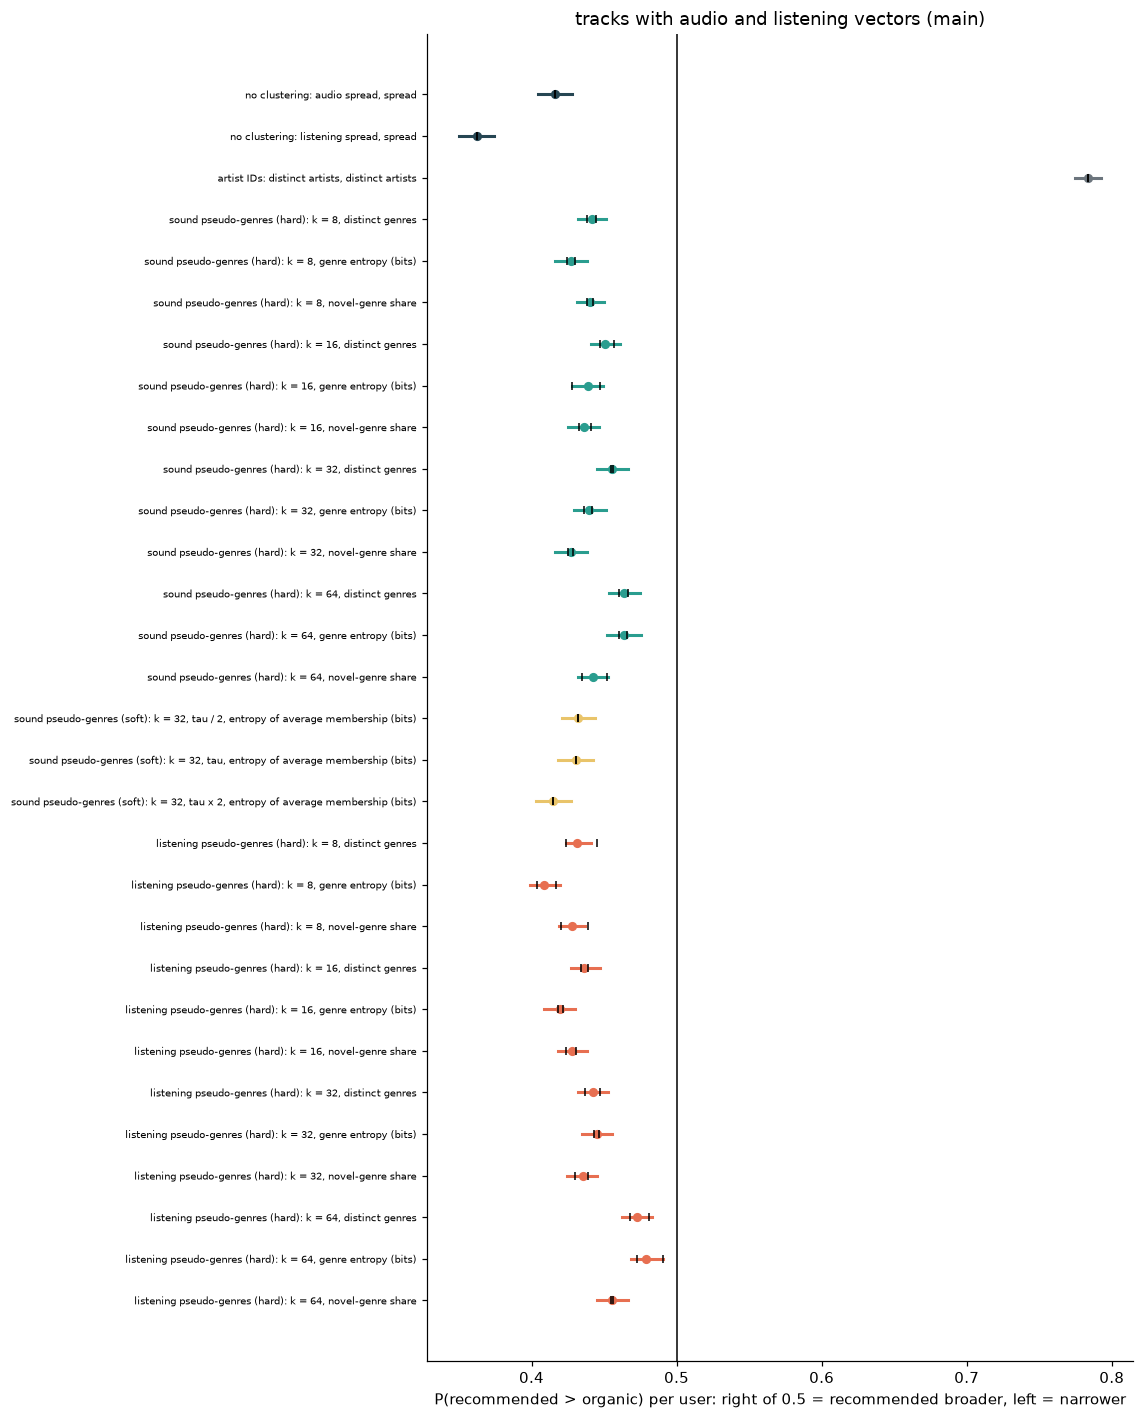

In [7]:
def forest(sample_name, ax):
    d = res[res["sample"] == sample_name].reset_index(drop=True)
    fam_col = {"no clustering": "#264653", "artist IDs": "#6c757d", "sound pseudo-genres (hard)": "#2a9d8f", "sound pseudo-genres (soft)": "#e9c46a", "listening pseudo-genres (hard)": "#e76f51"}
    y = np.arange(len(d))[::-1]
    for yi, r_ in zip(y, d.itertuples()):
        c = fam_col[r_.family]; ax.plot([r_.lo, r_.hi], [yi, yi], color=c, lw=2); ax.plot(r_.P, yi, "o", color=c, ms=5)
        ax.plot([r_.P_min, r_.P_max], [yi, yi], "|", color="k", ms=5, lw=0)
    ax.axvline(0.5, color="k", lw=1)
    ax.set_yticks(y); ax.set_yticklabels([f"{r_.family}: {r_.definition}, {r_.measure}" for r_ in d.itertuples()], fontsize=6.5)
    ax.set(title=sample_name, xlabel="P(recommended > organic) per user: right of 0.5 = recommended broader, left = narrower")
fig, ax = plt.subplots(figsize=(10.5, 13)); forest(MAIN, ax); plt.tight_layout(); plt.show()

### 3.1 Reading the comparison

**Every sound-based and listening-based definition says the same thing: recommended listening is narrower than organic listening. Only the artist definition points the other way.**

| Definition | Measure(s) | P(recommended > organic) | Reading |
|---|---|---|---|
| Audio spread (no clustering) | spread; median 0.66 organic, 0.64 recommended | **0.42** (0.41 to 0.43) | narrower |
| Listening spread (no clustering) | spread; median 0.70 organic, 0.66 recommended | **0.36** (0.35 to 0.37) | narrower |
| Distinct artists | median 30 organic, 35 recommended | **0.78** (0.77 to 0.79) | **broader** |
| Sound pseudo-genres, hard, k = 8, 16, 32, 64 | distinct genres, entropy, novel-genre share (12 comparisons) | 0.43 to 0.46 | narrower in all 12 |
| Sound pseudo-genres, soft (k = 32, three temperatures) | entropy of the average membership | 0.42 to 0.43 | narrower in all 3 |
| Listening pseudo-genres, hard, k = 8, 16, 32, 64 | distinct genres, entropy, novel-genre share (12 comparisons) | 0.41 to 0.48 | narrower in all 12 |

**All 29 comparisons that are based on sound or on listening show P below 0.5 with an interval that excludes 0.5.** The conclusion does not depend on the number of pseudo-genres (k = 8 to 64), on hard versus soft memberships, on whether genres are defined from sound or from listening, or on whether clusters are used at all (the two spread measures need no clustering and no choice of k).
The three random starts of k-means agree on the direction and differ by at most 0.02 in P. The listening-based spread gives the strongest result (P = 0.36: for roughly 6 in 10 users the recommended tracks lie closer together than the organic ones).

**How large is it?** Small in absolute terms, and smaller than with 100 tracks per stream (section 5). At k = 32 the median user has 10 distinct pseudo-genres among 40 organic tracks and 9 among 40 recommended tracks (entropy 2.59 against 2.51 bits; novel-genre share 17.5% against 13.3%). Per user the effect is modest: the recommended value is lower for 56% of users (entropy), 54% (novel-genre share), 58% (audio spread) and about 63% (listening spread); for distinct genres 48% are lower, 39% higher and the rest tie.
For measures with integer counts (distinct genres, distinct artists) many users tie, and ties count half in P, which pulls P towards 0.5; the spread measures have no ties and are the cleanest.

**Why the artist definition differs.** Artist IDs are not about sound: the recommender plays more different artists (median 35 against 30 per 40 tracks) that lie in fewer regions of the sound space. Together, "broader in artists, narrower in sound" is a statement about *two different notions of variety*, and which one a report calls "broader" has to be stated explicitly.

## 4. Sensitivity: universe and popularity

**Why.** The main sample contains only tracks with a listening vector (at least 20 plays), a popularity-biased subset. If the answer differed in the sample with all embedded tracks, or when the most popular tracks are removed, it would depend on which tracks we look at, and not only on how genre is defined.

**What we do.** We repeat the comparison in the sample with all embedded tracks (sound-based and artist definitions only, since listening vectors do not exist for all tracks) and in the main sample without the 20% most popular tracks, and place the three side by side for the definitions that all of them share.

**What we want to learn.** Whether the direction of each definition is the same in all three samples.

P(recommended > organic) in the three samples:
sample                                                            all embedded tracks  main sample without the 20% most popular tracks  tracks with audio and listening vectors (main)
family                     definition       measure                                                                                                                                   
artist IDs                 distinct artists distinct artists                    0.792                                            0.755                                           0.784
no clustering              audio spread     spread                              0.429                                            0.316                                           0.416
sound pseudo-genres (hard) k = 32           distinct genres                     0.457                                            0.358                                           0.455
                                      

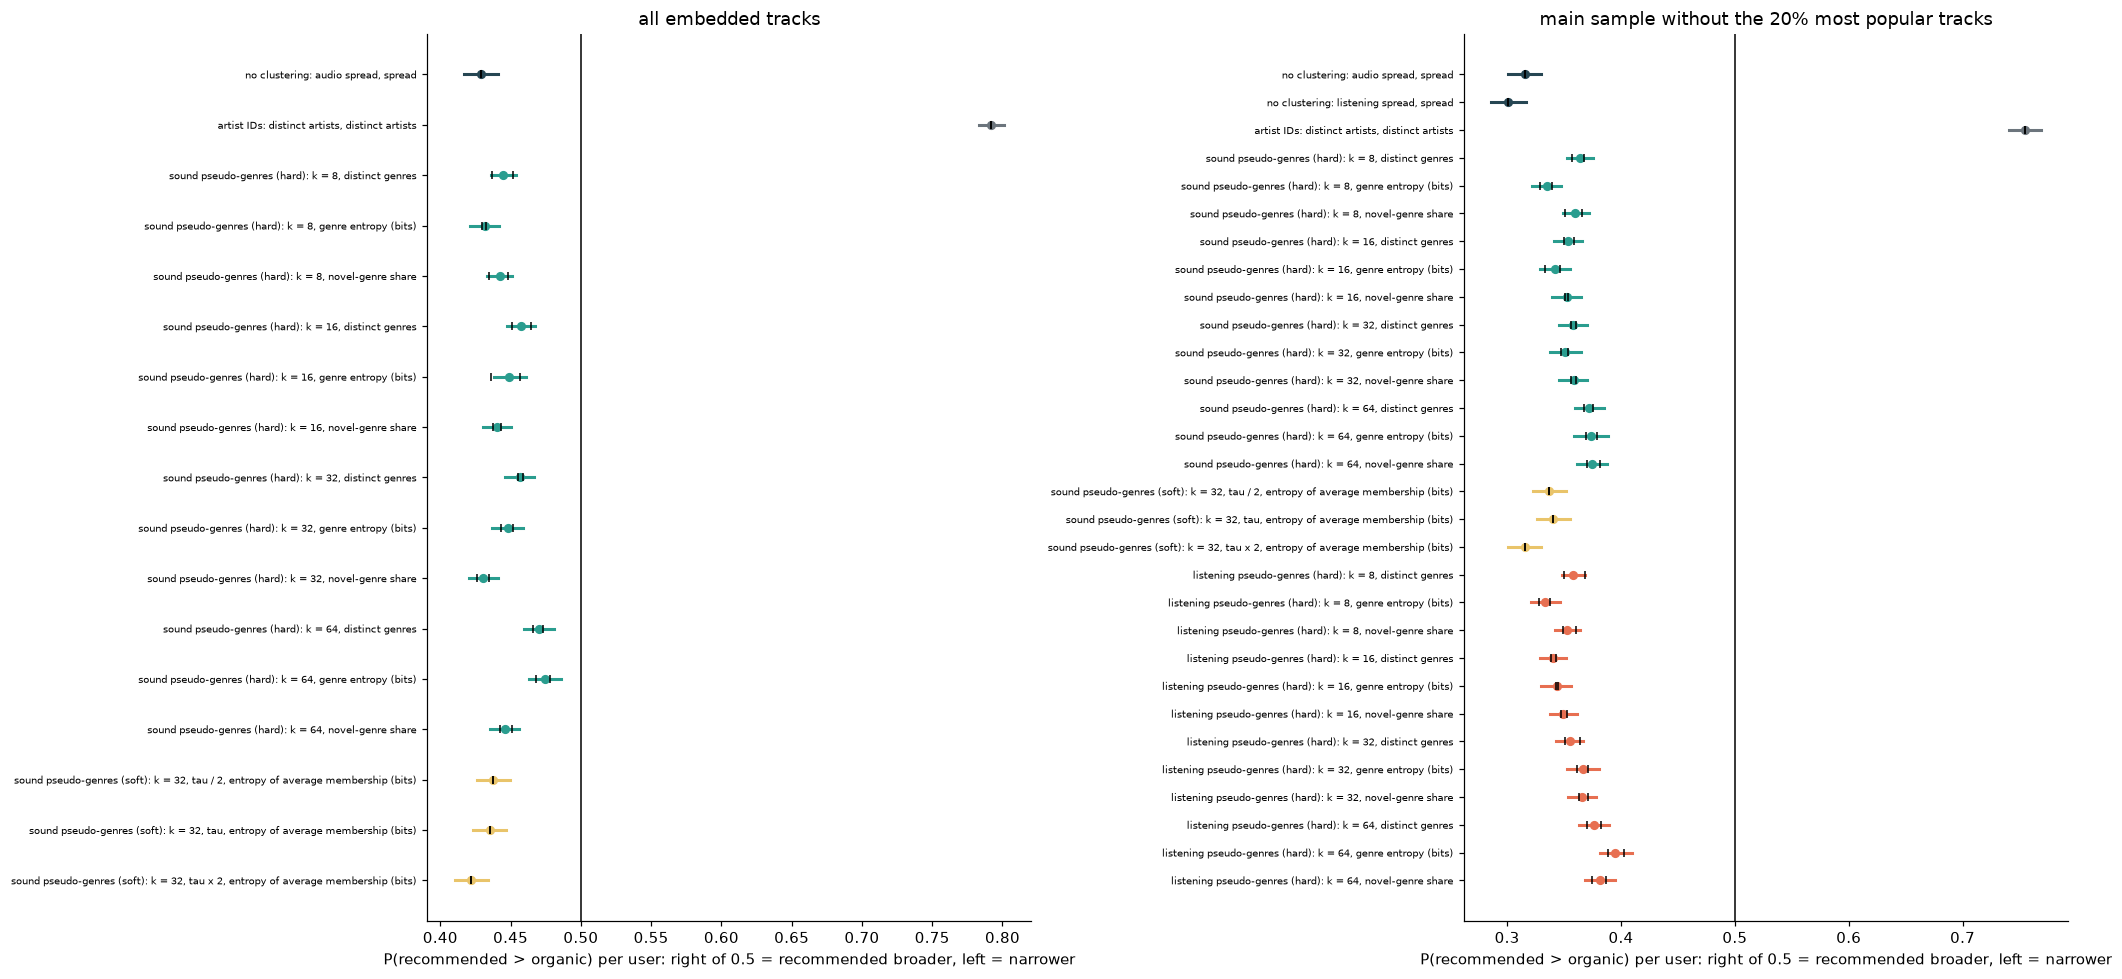

wrote RQ4_extension/genre_definitions_results.csv


In [8]:
shared = res[(res.definition.isin(["audio spread", "distinct artists"])) | ((res.definition == "k = 32") & res.family.str.startswith("sound")) | ((res.definition == "tau") & (res.family == "sound pseudo-genres (soft)"))]
pv = shared.pivot_table(index=["family", "definition", "measure"], columns="sample", values="P")
print("P(recommended > organic) in the three samples:"); print(pv.to_string(float_format=lambda x: f"{x:.3f}"))
fig, ax = plt.subplots(1, 2, figsize=(19, 9))
forest(res["sample"].unique()[0], ax[0]); forest(res["sample"].unique()[2], ax[1]); plt.tight_layout(); plt.show()
OUT = ROOT / "RQ4_extension"; OUT.mkdir(exist_ok=True); res.to_csv(OUT / "genre_definitions_results.csv", index=False)
print("wrote RQ4_extension/genre_definitions_results.csv")

### 4.1 Reading the sensitivity

**The direction is the same in all three samples.** For example, P(recommended > organic) for audio spread is 0.43 (all embedded tracks), 0.42 (main) and 0.32 (without the 20% most popular tracks); for distinct pseudo-genres at k = 32 0.457, 0.455 and 0.358; for distinct artists 0.79, 0.78 and 0.75.
Restricting to tracks that have a listening vector changes almost nothing (first two columns). Removing the most popular tracks makes the sound-based narrowing **stronger**, not weaker, so the result is not an effect of hits.

**Caveat.** The popularity-trimmed sample has only 3,958 users, those who also have at least 40 distinct tracks outside the top 20% in both streams, so it changes *who* is compared as well as *which tracks*; the two cannot be separated here.

## 5. Sensitivity: how many tracks per stream?

**Why.** The main sample keeps users with at least N distinct tracks in each stream and compares their first N. N = 100 left out 44% of all users and describes a long listening history; N = 40 is a normal listening stretch. If the answer depended on N, it would depend on an arbitrary choice.

**What we do.** We repeat the whole comparison of section 3 (main sample, all definitions) for N = 30, 40 and 100. Because N also changes *who* is included, we then repeat it for N = 30, 40 and 100 on **the same users** each time (those with at least 100 distinct tracks in both streams), so that only the number of tracks changes.

**What we want to learn.** Whether the direction holds for every N, whether the size of the effect changes with N, and whether a change comes from the tracks or from the users.

first 30 distinct tracks: 6,701 users (73% of all users)


first 40 distinct tracks: 6,441 users (70% of all users)


first 100 distinct tracks: 5,171 users (56% of all users)


done (25 s)

Pseudo-genre and spread comparisons (sound and listening based), by sample size:
     users  comparisons  P_min  P_max  narrower  broader
N                                                       
30    6701           29  0.404  0.504        27        0
40    6441           29  0.363  0.479        29        0
100   5171           29  0.250  0.390        29        0

P(recommended > organic) for key definitions:
N                                                                                      30    40    100
family                         definition       measure                                               
artist IDs                     distinct artists distinct artists                     0.782 0.784 0.756
listening pseudo-genres (hard) k = 32           distinct genres                      0.467 0.443 0.354
                                                genre entropy (bits)                 0.467 0.445 0.345
                                                novel-genre

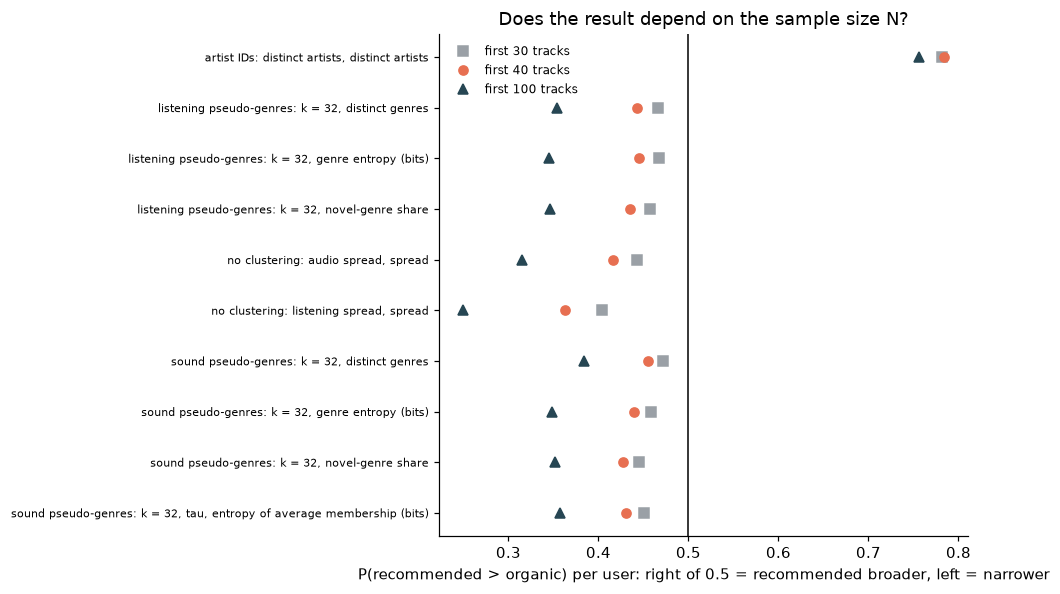

wrote RQ4_extension/genre_definitions_sample_size_results.csv


In [9]:
t0 = time.time(); sens_rows = []
for n in N_SENS:
    u_, it_ = build_sample(in_common, n)
    print(f"first {n} distinct tracks: {len(u_):,} users ({len(u_) / n_users:.0%} of all users)")
    sens_rows += evaluate_sample(f"first {n} distinct tracks", it_, with_listening=True)
sens = pd.DataFrame(sens_rows); sens["N"] = sens["sample"].str.extract(r"first (\d+)")[0].astype(int)
sens["direction"] = np.where(sens.hi < 0.5, "narrower", np.where(sens.lo > 0.5, "broader", "no clear difference"))
print(f"done ({time.time() - t0:.0f} s)\n")

pg = sens[~sens.definition.isin(["audio spread", "listening spread", "distinct artists"])]
print("Pseudo-genre and spread comparisons (sound and listening based), by sample size:")
print(sens[sens.family != "artist IDs"].groupby("N").agg(users=("users", "first"), comparisons=("P", "size"), P_min=("P", "min"), P_max=("P", "max"),
      narrower=("direction", lambda d: (d == "narrower").sum()), broader=("direction", lambda d: (d == "broader").sum())).to_string(float_format=lambda x: f"{x:.3f}"))
key = sens[(sens.definition.isin(["audio spread", "listening spread", "distinct artists"])) | (sens.definition.isin(["k = 32", f"k = {K_SOFT}, tau"]) & sens.measure.isin(["distinct genres", "genre entropy (bits)", "novel-genre share", "entropy of average membership (bits)"]))]
pvN = key.pivot_table(index=["family", "definition", "measure"], columns="N", values="P"); print("\nP(recommended > organic) for key definitions:"); print(pvN.to_string(float_format=lambda x: f"{x:.3f}"))
print("\nMedian per user: organic / recommended")
print(key.pivot_table(index=["family", "definition", "measure"], columns="N", values=["organic_median", "recommended_median"]).to_string(float_format=lambda x: f"{x:.2f}"))

fig, ax = plt.subplots(figsize=(9, 5.5)); lab_ = [f"{f.split(' (')[0]}: {d}, {m}" for f, d, m in pvN.index]; y = np.arange(len(pvN))[::-1]
for n, c, mk in zip(N_SENS, ["#9aa0a6", ACC, REAL], ["s", "o", "^"]): ax.plot(pvN[n], y, mk, color=c, label=f"first {n} tracks", ms=6)
ax.axvline(0.5, color="k", lw=1); ax.set_yticks(y); ax.set_yticklabels(lab_, fontsize=7); ax.legend(frameon=False, fontsize=8)
ax.set(xlabel="P(recommended > organic) per user: right of 0.5 = recommended broader, left = narrower", title="Does the result depend on the sample size N?"); plt.tight_layout(); plt.show()
sens.drop(columns="direction").to_csv(OUT / "genre_definitions_sample_size_results.csv", index=False); print("wrote RQ4_extension/genre_definitions_sample_size_results.csv")

In [10]:
# is the weaker result at small N because of fewer tracks, or because of which users are included? Same users (those with at least 100 tracks in both streams) at every N:
u100, _ = build_sample(in_common, 100); same_rows = []
for n in N_SENS:
    u_n, it_n = build_sample(in_common, n); keep_u = np.isin(u_n, u100)
    same_rows += evaluate_sample(f"first {n} distinct tracks, the {len(u100):,} users with at least 100", it_n[keep_u], with_listening=True)
same = pd.DataFrame(same_rows); same["N"] = same["sample"].str.extract(r"first (\d+)")[0].astype(int)
keys_ = same[(same.definition.isin(["audio spread", "listening spread", "distinct artists"])) | (same.definition.isin(["k = 32", f"k = {K_SOFT}, tau"]) & same.measure.isin(["distinct genres", "genre entropy (bits)", "novel-genre share", "entropy of average membership (bits)"]))]
print(f"P(recommended > organic) for the same {len(u100):,} users at each N:"); print(keys_.pivot_table(index=["family", "definition", "measure"], columns="N", values="P").to_string(float_format=lambda x: f"{x:.3f}"))
sp_ = same[same.family != "artist IDs"].groupby("N").agg(P_min=("P", "min"), P_max=("P", "max"), narrower=("hi", lambda h: (h < 0.5).sum()), comparisons=("P", "size")); print("\nAll 29 sound- and listening-based comparisons, same users:"); print(sp_.to_string(float_format=lambda x: f"{x:.3f}"))
same.to_csv(OUT / "genre_definitions_sample_size_same_users_results.csv", index=False)

P(recommended > organic) for the same 5,171 users at each N:
N                                                                                      30    40    100
family                         definition       measure                                               
artist IDs                     distinct artists distinct artists                     0.783 0.784 0.756
listening pseudo-genres (hard) k = 32           distinct genres                      0.461 0.441 0.354
                                                genre entropy (bits)                 0.460 0.442 0.345
                                                novel-genre share                    0.451 0.430 0.347
no clustering                  audio spread     spread                               0.440 0.414 0.315
                               listening spread spread                               0.396 0.361 0.250
sound pseudo-genres (hard)     k = 32           distinct genres                      0.472 0.456 0.384
            

### 5.1 Reading the sample-size sensitivity

**The direction is the same for every N, but the effect grows with N.** P(recommended > organic) for audio spread is 0.44 (N = 30), 0.42 (N = 40) and 0.32 (N = 100); for listening spread 0.40, 0.36 and 0.25; for the entropy of sound pseudo-genres at k = 32 0.46, 0.44 and 0.35. Distinct artists hardly change (0.78, 0.78, 0.76) and stay on the *broader* side. At N = 40 and N = 100 all 29 sound- and listening-based comparisons are narrower with an interval that excludes 0.5; at N = 30, 27 of 29 are, and the two others (listening pseudo-genres at k = 64, distinct genres and entropy; P = 0.50 for both) show no clear difference. The samples contain 6,701 users (N = 30, 73% of all users), 6,441 (N = 40, 70%) and 5,171 (N = 100, 56%).

**It is the number of tracks, not the users.** On the same 5,171 users the pattern is the same: audio spread 0.44, 0.41, 0.32; listening spread 0.40, 0.36, 0.25 (N = 30, 40, 100), and 28, 29 and 29 of the 29 comparisons are narrower. So users with long histories do not explain the stronger result at N = 100.

**What it means.** The shorter the stretch of listening, the smaller the difference between the streams; the first tracks of the recommended stream are almost as varied as organic ones, and the narrowing builds up as more recommended tracks are played, which is what section 6 looks at directly. Choosing N = 40 as the main setting makes the result *weaker* than with N = 100 and does not reverse it.

## 6. Early versus late: does the variety of recommended listening fade?

**Why.** If the recommender keeps to similar sound (pseudo-genres) as a stretch of listening goes on, recommended listening should start about as varied as organic listening and become narrower later. Section 5 hints at this (the difference grows with N). Here we test it directly.

**What we do.** We take the main sample (N = 40, tracks of each stream in time order) and cut each stream into windows of 10 tracks (1-10, 11-20, 21-30, 31-40).
- *6.1:* variety **inside** each window, for organic and recommended tracks, and how it changes from the first to the last window.
- *6.2:* a **discovery curve**: how many distinct pseudo-genres (k = 32) a user has seen after 1, 2, ..., 40 tracks of a stream, and how many *new* pseudo-genres each window adds.
- *6.3:* the same idea inside real **sessions** (runs of listens without a pause longer than 30 minutes): sessions with at least 40 distinct tracks, where we follow the share of recommended tracks and the variety through the session.

**Caveat on "early" and "late".** In 6.1 and 6.2 the position is the order of the user's distinct tracks *within a stream*; the 40 tracks may cover many days and sessions. 6.3 is the only part that is truly position within a session, and there both streams are mixed. Windows of 10 tracks have few distinct pseudo-genres (at most 10), so the values are coarse; we report intervals over users.

### 6.1 Variety inside each window of 10 tracks

6,441 users; windows of 10 distinct tracks of each stream; mean per user

                              measure window  organic  recommended     P
                         audio spread   1-10    0.571        0.601 0.531
                         audio spread  11-20    0.575        0.593 0.508
                         audio spread  21-30    0.579        0.593 0.500
                         audio spread  31-40    0.579        0.590 0.494
                     listening spread   1-10    0.596        0.611 0.519
                     listening spread  11-20    0.594        0.599 0.489
                     listening spread  21-30    0.599        0.602 0.482
                     listening spread  31-40    0.602        0.601 0.478
                     distinct artists   1-10    7.649        9.690 0.759
                     distinct artists  11-20    7.741        9.735 0.749
                     distinct artists  21-30    7.840        9.741 0.739
                     distinct artists  31-40    7.

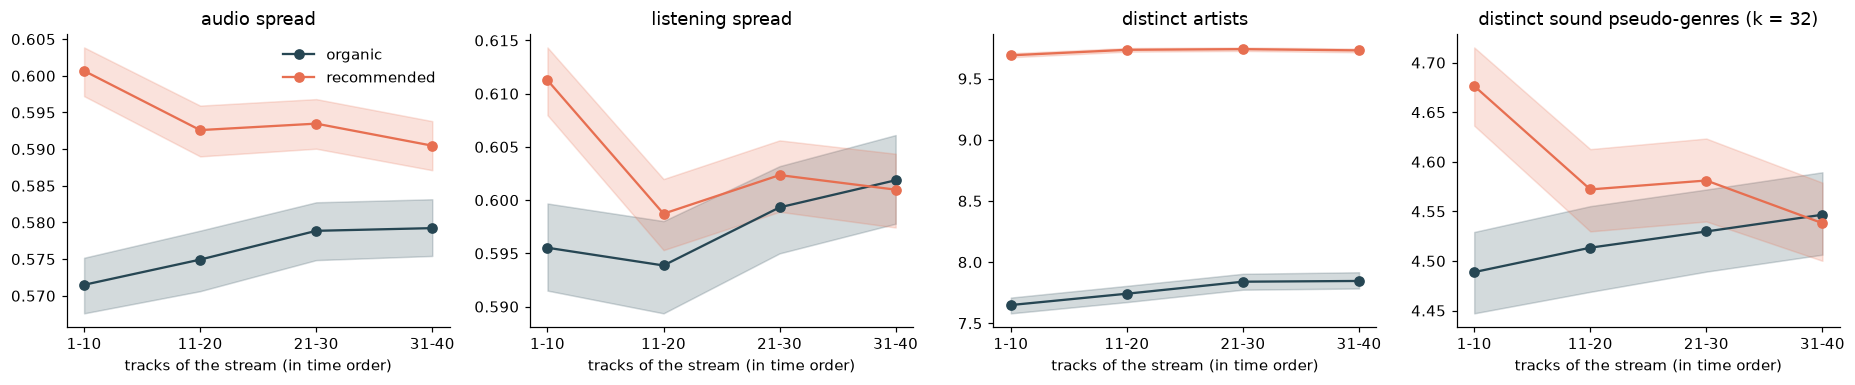


Change from the first to the last window (mean per user, 95% bootstrap interval), and recommended minus organic change:


                              measure            organic_change        recommended_change             rec_minus_org  share_users_recommended_declines_more
                         audio spread +0.008 (+0.003 to +0.013) -0.010 (-0.014 to -0.007) -0.018 (-0.024 to -0.012)                                   0.53
                     listening spread +0.006 (+0.002 to +0.012) -0.010 (-0.014 to -0.007) -0.017 (-0.023 to -0.011)                                   0.53
                     distinct artists +0.197 (+0.125 to +0.272) +0.040 (+0.019 to +0.061) -0.156 (-0.231 to -0.081)                                   0.40
distinct sound pseudo-genres (k = 32) +0.058 (+0.012 to +0.107) -0.138 (-0.183 to -0.098) -0.196 (-0.258 to -0.134)                                   0.51


In [11]:
ITEMS = samples[MAIN]                      # (users, 2, N_TRACKS): axis 1 is 0 = recommended, 1 = organic; tracks in time order
nW = ITEMS.shape[2] // WIN; wlab = [f"{w * WIN + 1}-{(w + 1) * WIN}" for w in range(nW)]; U_ = ITEMS.shape[0]
BI = rng.integers(0, U_, (N_BOOT, U_))     # one set of bootstrap users, shared by all comparisons below
def win_measures(items):                   # every function returns (organic, recommended)
    hs = [hard_measures(items, lab_sound[(32, s)], 32)["distinct genres"] for s in range(N_SEEDS)]
    return {"audio spread": spread_measure(items, EN, item_row), "listening spread": spread_measure(items, LV, cidx), "distinct artists": artist_measure(items),
            "distinct sound pseudo-genres (k = 32)": (np.mean([h[0] for h in hs], axis=0), np.mean([h[1] for h in hs], axis=0))}
WM = [win_measures(ITEMS[:, :, w * WIN:(w + 1) * WIN]) for w in range(nW)]
names = list(WM[0])
def ci(x): b = x[BI].mean(axis=1); return x.mean(), np.quantile(b, 0.025), np.quantile(b, 0.975)

rows = []
for m_ in names:
    for w in range(nW):
        o, r = WM[w][m_]; rows.append(dict(measure=m_, window=wlab[w], organic=o.mean(), recommended=r.mean(), P=((r > o) + 0.5 * (r == o)).mean()))
tab = pd.DataFrame(rows); print(f"{U_:,} users; windows of {WIN} distinct tracks of each stream; mean per user\n"); print(tab.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

fig, axs = plt.subplots(1, 4, figsize=(17, 3.6)); x = np.arange(nW)
for a, m_ in zip(axs, names):
    for j, c, lab in [(0, REAL, "organic"), (1, ACC, "recommended")]:
        v = np.array([ci(WM[w][m_][j]) for w in range(nW)]); a.plot(x, v[:, 0], "o-", color=c, label=lab); a.fill_between(x, v[:, 1], v[:, 2], color=c, alpha=0.2)
    a.set_xticks(x); a.set_xticklabels(wlab); a.set(title=m_, xlabel="tracks of the stream (in time order)")
axs[0].legend(frameon=False); plt.tight_layout(); plt.show()

print("\nChange from the first to the last window (mean per user, 95% bootstrap interval), and recommended minus organic change:")
rows = []
for m_ in names:
    d = {j: WM[-1][m_][j] - WM[0][m_][j] for j in (0, 1)}; diff = d[1] - d[0]
    rows.append(dict(measure=m_, organic_change="%+.3f (%+.3f to %+.3f)" % ci(d[0]), recommended_change="%+.3f (%+.3f to %+.3f)" % ci(d[1]), rec_minus_org="%+.3f (%+.3f to %+.3f)" % ci(diff),
                     share_users_recommended_declines_more=(diff < 0).mean()))
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda x: f"{x:.2f}"))

**What we see.** In the first 10 tracks recommended listening is, if anything, slightly *broader* in sound than organic listening (audio spread 0.601 against 0.571, P = 0.53; 4.68 against 4.49 distinct pseudo-genres). The gap closes as listening goes on: in tracks 31-40 the share of users with broader recommended listening is 0.49 for audio spread and for pseudo-genres, and 0.48 for listening spread (below 0.5). From the first to the last window, recommended variety **falls** (audio spread -0.010, 95% interval -0.014 to -0.007; distinct pseudo-genres -0.14, -0.18 to -0.10) while organic variety **rises** slightly (+0.008 and +0.06). The difference in change is -0.018 for audio spread (-0.024 to -0.012) and -0.20 pseudo-genres (-0.26 to -0.13). Distinct artists do not fade: recommended stays broader throughout (P = 0.76 in the first window, 0.74 in the last).

**How strong is it?** Weak. The changes are a few per cent of the level, and the share of users whose recommended variety declines *more* than their organic variety is only 51% to 53% for the sound-based measures. This is a small shift of the typical user, not a collapse for each user.

### 6.2 Discovery of pseudo-genres

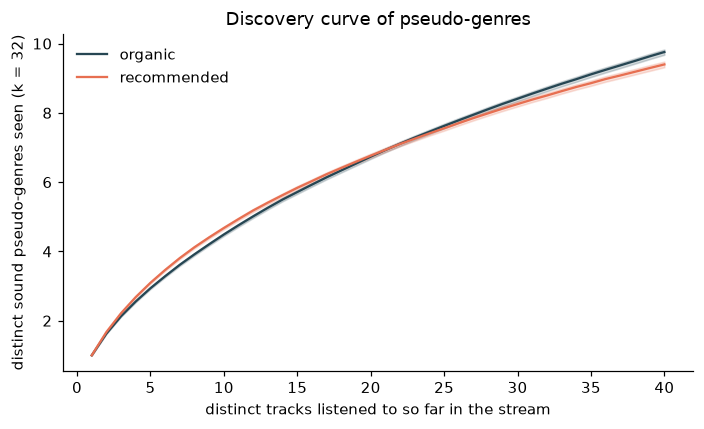

New pseudo-genres (k = 32, mean of 3 starts) first seen in each window of 10 tracks, mean per user:
window  organic_new_genres  recommended_new_genres    P
  1-10                4.49                    4.68 0.52
 11-20                2.25                    2.09 0.47
 21-30                1.67                    1.49 0.46
 31-40                1.35                    1.14 0.45

distinct pseudo-genres after all 40 tracks: organic 9.8, recommended 9.4


In [12]:
def cum_distinct(items, lab, K):
    G = lab[items].astype(np.int64); U, _, n = G.shape; seen = np.zeros((U, 2, K), bool); out = np.empty((U, 2, n))
    for j in range(n): np.put_along_axis(seen, G[:, :, j:j + 1], True, axis=2); out[:, :, j] = seen.sum(-1)
    return out
CD = np.mean([cum_distinct(ITEMS, lab_sound[(32, s)], 32) for s in range(N_SEEDS)], axis=0)    # (users, 2, N_TRACKS): distinct pseudo-genres seen so far
fig, ax = plt.subplots(figsize=(6.5, 4)); xx = np.arange(1, ITEMS.shape[2] + 1)
for j, c, lab in [(0, REAL, "organic"), (1, ACC, "recommended")]:
    v = np.array([ci(CD[:, 1 - j, t]) for t in range(len(xx))]); ax.plot(xx, v[:, 0], color=c, label=lab); ax.fill_between(xx, v[:, 1], v[:, 2], color=c, alpha=0.2)
ax.set(xlabel="distinct tracks listened to so far in the stream", ylabel="distinct sound pseudo-genres seen (k = 32)", title="Discovery curve of pseudo-genres"); ax.legend(frameon=False); plt.tight_layout(); plt.show()
rows = []
for w in range(nW):
    a, b = w * WIN - 1, (w + 1) * WIN - 1
    new = {j: CD[:, 1 - j, b] - (CD[:, 1 - j, a] if a >= 0 else 0) for j in (0, 1)}
    rows.append(dict(window=wlab[w], organic_new_genres=new[0].mean(), recommended_new_genres=new[1].mean(), P=((new[1] > new[0]) + 0.5 * (new[1] == new[0])).mean()))
print(f"New pseudo-genres (k = 32, mean of 3 starts) first seen in each window of {WIN} tracks, mean per user:"); print(pd.DataFrame(rows).to_string(index=False, float_format=lambda x: f"{x:.2f}"))
print("\ndistinct pseudo-genres after all %d tracks: organic %.1f, recommended %.1f" % (ITEMS.shape[2], CD[:, 1, -1].mean(), CD[:, 0, -1].mean()))

**What we see.** Both streams discover pseudo-genres quickly at first and then flatten: the first 10 tracks reach 4.5 (organic) and 4.7 (recommended) pseudo-genres, and each later window adds fewer *new* ones (organic 2.25, 1.67, 1.35; recommended 2.09, 1.49, 1.14). Recommended listening starts ahead (P = 0.52 for new pseudo-genres in the first window) and falls behind from the second window on (P = 0.47, 0.46, 0.45), so after 40 tracks organic listening has covered 9.8 distinct pseudo-genres against 9.4 for recommended listening.

**What this means.** The narrowing in the whole-sample comparison (section 3) mainly reflects recommended listening **returning to pseudo-genres it has already played** in later windows, and less a narrower range within any 10 tracks. This fits section 5: the longer the stretch, the larger the difference.

### 6.3 Inside real sessions

112,076 sessions with at least 40 distinct embedded tracks, from 6,598 users (72% of all users); share of recommended tracks in them 64.2%


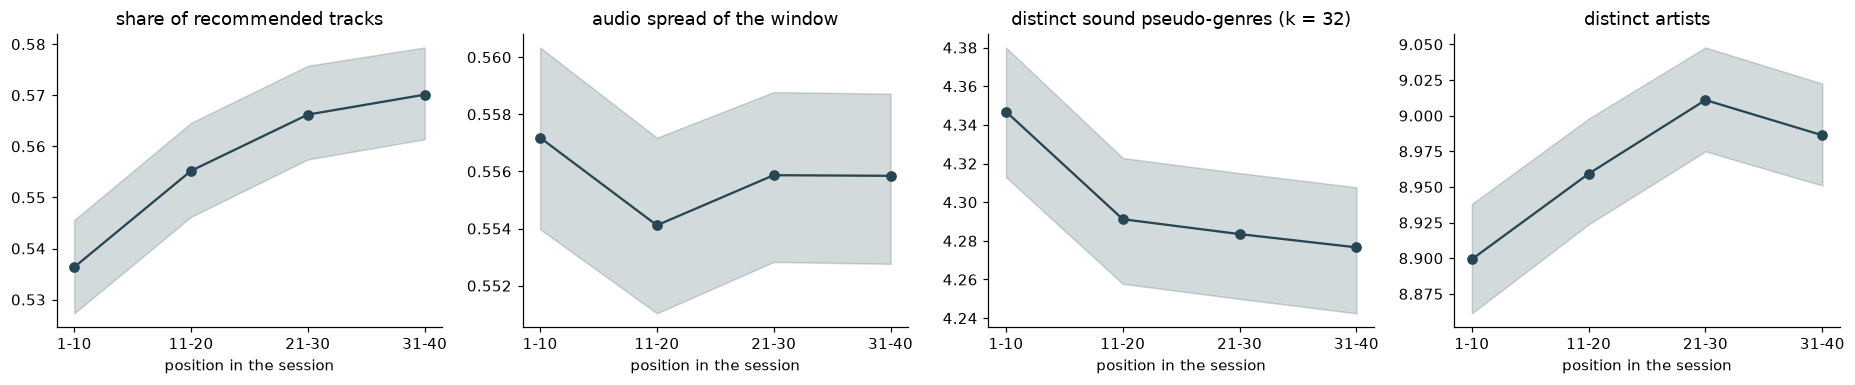

Mean per user over their sessions (6,598 users):
                              measure  window 1-10  window 11-20  window 21-30  window 31-40      change_first_to_last
          share of recommended tracks        0.536         0.555         0.566         0.570 +0.034 (+0.029 to +0.039)
           audio spread of the window        0.557         0.554         0.556         0.556 -0.001 (-0.003 to +0.001)
distinct sound pseudo-genres (k = 32)        4.347         4.291         4.283         4.277 -0.070 (-0.095 to -0.048)
                     distinct artists        8.899         8.959         9.011         8.986 +0.087 (+0.057 to +0.116)


In [13]:
# true within-session position: sessions (30-minute gap rule, as in section 1.2) with at least N_TRACKS distinct embedded tracks, first N_TRACKS tracks of each
m = np.flatnonzero(in_all[item]); s_m, it_m = sid[m], item[m].astype(np.int64); og_m, u_m = org[m].astype(np.int64), uid_idx[m].astype(np.int64)
_, fi = np.unique(s_m * (int(item.max()) + 1) + it_m, return_index=True); fi.sort(); s_m, it_m, og_m, u_m = s_m[fi], it_m[fi], og_m[fi], u_m[fi]
_, inv, cnt_s = np.unique(s_m, return_inverse=True, return_counts=True); rk = rank_in_sorted_groups(s_m)
sel = (rk < N_TRACKS) & (cnt_s[inv] >= N_TRACKS)
SI, SO, SU = it_m[sel].reshape(-1, N_TRACKS), og_m[sel].reshape(-1, N_TRACKS), u_m[sel].reshape(-1, N_TRACKS)[:, 0]
print(f"{len(SI):,} sessions with at least {N_TRACKS} distinct embedded tracks, from {len(np.unique(SU)):,} users ({len(np.unique(SU)) / n_users:.0%} of all users); "
      f"share of recommended tracks in them {1 - SO.mean():.1%}")
def n_distinct(L_):  # distinct labels per row
    A = np.sort(L_, axis=1); return 1 + (np.diff(A, axis=1) != 0).sum(axis=1)
uu, uinv = np.unique(SU, return_inverse=True); cntu = np.bincount(uinv)
def per_user(v): return np.bincount(uinv, weights=v) / cntu          # mean over the user's sessions
SM = {k: [] for k in ["share of recommended tracks", "audio spread of the window", "distinct sound pseudo-genres (k = 32)", "distinct artists"]}
for w in range(nW):
    a = slice(w * WIN, (w + 1) * WIN); It = SI[:, a]; X = EN[item_row[It]].sum(axis=1)
    SM["share of recommended tracks"].append(per_user(1 - SO[:, a].mean(axis=1)))
    SM["audio spread of the window"].append(per_user(1 - ((X.astype(np.float64) ** 2).sum(-1) - WIN) / (WIN * (WIN - 1))))
    SM["distinct sound pseudo-genres (k = 32)"].append(np.mean([per_user(n_distinct(lab_sound[(32, s)][It])) for s in range(N_SEEDS)], axis=0))
    SM["distinct artists"].append(per_user(n_distinct(art_of_item[It])))
BS = rng.integers(0, len(uu), (N_BOOT, len(uu)))
def ci_s(x): b = x[BS].mean(axis=1); return x.mean(), np.quantile(b, 0.025), np.quantile(b, 0.975)
fig, axs = plt.subplots(1, 4, figsize=(17, 3.6)); x = np.arange(nW); rows = []
for a, (m_, lst) in zip(axs, SM.items()):
    v = np.array([ci_s(z) for z in lst]); a.plot(x, v[:, 0], "o-", color=REAL); a.fill_between(x, v[:, 1], v[:, 2], color=REAL, alpha=0.2); a.set_xticks(x); a.set_xticklabels(wlab); a.set(title=m_, xlabel="position in the session")
    d = lst[-1] - lst[0]; rows.append(dict(measure=m_, **{f"window {wlab[w]}": v[w, 0] for w in range(nW)}, change_first_to_last="%+.3f (%+.3f to %+.3f)" % ci_s(d)))
plt.tight_layout(); plt.show(); print(f"Mean per user over their sessions ({len(uu):,} users):"); print(pd.DataFrame(rows).to_string(index=False, float_format=lambda x: f"{x:.3f}"))

**What we see.** There are 112,076 sessions with at least 40 distinct embedded tracks, from 6,598 users (72% of all users); 64% of the tracks in these sessions are recommended. The **share of recommended tracks grows through the session**, from 53.6% in tracks 1-10 to 57.0% in tracks 31-40 (+3.4 points, interval +2.9 to +3.9), so the recommender does take over a little as the session goes on. The **variety of the tracks in a window hardly changes**: audio spread is flat (-0.001, interval -0.003 to +0.001), distinct pseudo-genres per window fall by 0.07 of 4.3 (-0.095 to -0.048, about 1.6%), and distinct artists rise by 0.09.

**Limits.** Sessions here mix the two streams, so this cannot say whether recommended tracks specifically become less varied; and only long sessions (40 or more distinct tracks) are included.

### 6.4 What the position analysis says about the hypothesis

**Is there more variety early that fades?** Partly, and only weakly.
1. *Per stream (6.1, 6.2):* yes in direction. Recommended listening starts slightly *broader* in sound than organic (P = 0.52-0.53 in the first window), and by tracks 31-40 it is at or slightly below organic (P = 0.48-0.49); it discovers fewer new pseudo-genres in every later window. The shift is small (about 0.2 pseudo-genres in windows with 4.5).
2. *Within sessions (6.3):* the recommender's **share** rises by about 3 points, but the sound variety of a window is nearly constant, so there is no clear fade of variety inside a session of 40 tracks.
3. *In artists:* no fade; recommended listening stays broader in artists in every window.
4. *Association only:* these are positions in logged listening; the data cannot say whether the recommender or the listener's own behaviour causes the pattern.

## 7. Summary and limitations

**What this adds to RQ4 and to the main question.**
1. **The finding "recommended listening is narrower in sound and broader in artists" does not depend on how genre is defined.** All 29 sound-based and listening-based comparisons point the same way (P(recommended > organic) between 0.36 and 0.48 with intervals excluding 0.5), for k = 8 to 64, hard and soft memberships, pseudo-genres from sound and from listening, and two measures that use no clustering at all. The artist definition points the other way (P = 0.78).
2. **It is not an artefact of the pseudo-genre construction.** The pseudo-genres define the unit in which "broader" is counted, and their number and boundaries are arbitrary (they come from a continuum); the clustering-free measures and the listening-based genres show that the answer does not hinge on that arbitrariness.
3. **It is not an effect of popular tracks**: removing the 20% most popular tracks strengthens it.
4. **The effect is small and grows with the length of the listening stretch.** For the first 40 distinct tracks per stream the median user has about one pseudo-genre fewer out of 10 at k = 32 (P = 0.36 to 0.48 across sound and listening definitions). With 30 tracks the effect is smaller (27 of 29 comparisons still narrower); with 100 it is larger (P = 0.25 to 0.39). The same users show the same pattern at each N, so it is the number of tracks and not the choice of users.
5. **Early versus late.** In the first 10 tracks recommended listening is slightly broader in sound than organic; by tracks 31-40 it is at or slightly below it, because it adds fewer new pseudo-genres in each later window. Inside sessions the recommended share rises by about 3 points while window variety stays nearly flat. Distinct artists do not fade.

**Limitations.**
- *Users with at least a short history only.* Users need at least 40 distinct tracks in each stream (70% of users in the main sample, 43% in the trimmed one; 56% with the earlier N = 100). Users with less listening are not described.
- *The first 40 distinct tracks of each stream in time order.* The two streams of one user may cover different periods; this was not controlled. The position analysis (6.1, 6.2) refers to the order within a stream, not to time within a session; only 6.3 uses sessions, and it covers long sessions only and mixes the two streams.
- *Windows of 10 tracks are coarse* (at most 10 distinct pseudo-genres), and the early-versus-late differences are small; they are averages over users, not a fade for each user.
- *Listening-based definitions describe well-known tracks* (at least 20 plays), and the item2vec settings were fixed in advance, not tuned.
- *Soft memberships are a simple softmax of cosine similarity*; the temperature was set by a rule (average largest membership 0.5; 0.8 and 0.18 for half and double the value), not optimised.
- *One clustering method* (spherical k-means) with three starts; the bootstrap intervals reflect the sampling of users, and the spread between starts is reported separately.
- *Sound and listening are not independent* (the same tracks have similar sound and similar listening), so the agreement of the two kinds of definition is partly expected.
- *Associations only.* The recommended and the organic stream differ in how tracks are chosen (an algorithm against the user), and this notebook does not say why one is narrower.